# 03 · Une campagne, pas à pas : du contrefactuel au verdict

Ce notebook prend **une** campagne mesurable et déroule tout le protocole dessus : l'ajustement de pré-période,
le contrefactuel et ses intervalles, les effets en unités (pendant, après, net), le placebo dans le temps, le
placebo dans l'espace avec isolation des donneurs, la sensibilité au pool, la comparaison avec les autres
estimateurs, et le verdict de crédibilité. Tout ce que `nr estimate` fait en boucle sur chaque campagne.
Le modèle est celui de la veille (`causal_ts`) : niveau local + régression statique sur les donneurs et le
calendrier, maximum de vraisemblance sur la pré-période, trajectoires simulées conjointement.

In [1]:
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from novaretail import viz
from novaretail.backtest import ESTIMATORS, isolate, placebo_space, placebo_time, pool_sensitivity
from novaretail.data import RESULTS
from novaretail.donors import RegistryRule, eligible_donors, pool_units
from novaretail.estimate import PROTOCOL, assemble, credibility, estimate_campaign
from novaretail.workspace import load_world

warnings.simplefilter("ignore")
viz.setup()
export = viz.exporter("../figures")
w = load_world()
est_all = pd.read_parquet(RESULTS / "estimates.parquet")
with open(RESULTS / "estimates.pkl", "rb") as fh:
    kept = pickle.load(fh)
meas = est_all[est_all["status"] == "measurable"].sort_values("during_cf_units", ascending=False)
cid = int(next(c for c in meas["campaign_id"] if int(c) in kept))
camp = meas.set_index("campaign_id").loc[cid]
print(f"campagne {cid} : magasin {camp['store_nbr']}, {camp['family']}, du {pd.Timestamp(camp['start']).date()} "
      f"au {pd.Timestamp(camp['end']).date()} ({camp['length']} jours), horizon {camp['n_post']} jours, "
      f"{camp['n_donors']} donneurs")

campagne 296 : magasin 5, BEVERAGES, du 2016-08-30 au 2016-09-11 (13 jours), horizon 14 jours, 8 donneurs


## 1. La pré-période : ce que les donneurs expliquent

**Intuition.** Le contrefactuel n'est crédible que si le modèle sait prévoir la série **avant** la campagne.
L'ajustement un pas en avant (filtre de Kalman) est la bonne mesure : à chaque jour de pré-période, la
prévision n'utilise que le passé. Son R², la couverture de son intervalle à 95 % et l'absence d'autocorrélation
des résidus (Ljung-Box) sont les trois contrôles du protocole.

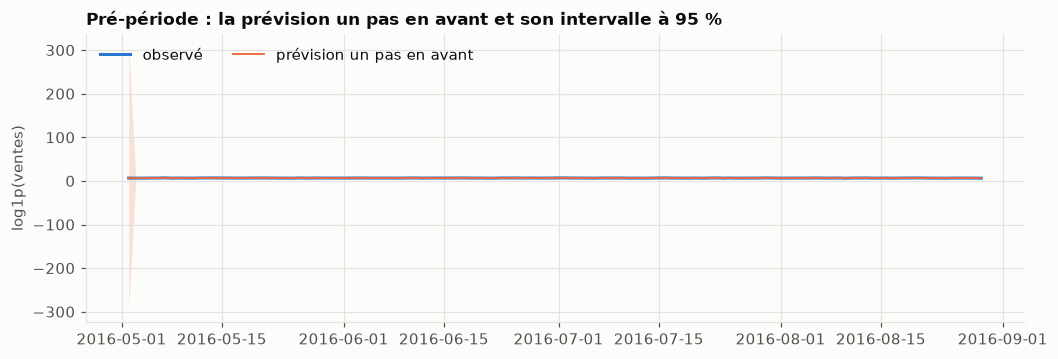

{'rmse_pre': 0.076, 'r2_one_step': 0.731, 'coverage_one_step': 0.943, 'ljung_box_p': 0.319, 'n_pre_obs': 106}


In [2]:
tab = eligible_donors(w.wide_raw, w.wide_promo, w.usable, w.stores, camp, RegistryRule())
pool = pool_units(tab)
y, X = assemble(w.wide, w.calendars, camp, pool)
est = estimate_campaign(y, X, camp, pool, param_draws=40, nsim=3000)
r = est.result
pre = y.loc[: r.pre_end]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(pre.index, pre.values, color=viz.BLUE, label="observé")
ax.plot(r.fit.index, r.fit["mean"], color=viz.ORANGE, linewidth=1.2, label="prévision un pas en avant")
ax.fill_between(r.fit.index, r.fit["lower"], r.fit["upper"], color=viz.ORANGE, alpha=0.18, linewidth=0)
ax.set_title("Pré-période : la prévision un pas en avant et son intervalle à 95 %")
ax.set_ylabel("log1p(ventes)")
ax.legend(loc="upper left", ncol=2)
export(fig, "nb03_prefit")
plt.show()
print({k: round(v, 3) for k, v in est.quality.items()})

## 2. Le contrefactuel et ses trois lectures

**Exemple.** Les trois panneaux classiques : observé contre contrefactuel, effet ponctuel, effet cumulé. La bande
orange est la fenêtre de campagne ; l'horizon de 14 jours qui suit sert à voir le creux de *pull-forward*. Les
intervalles proviennent de 3 000 trajectoires simulées conjointement, avec 40 tirages de paramètres dans la loi
asymptotique du maximum de vraisemblance (l'équivalent fréquentiste de l'intégration MCMC de CausalImpact).

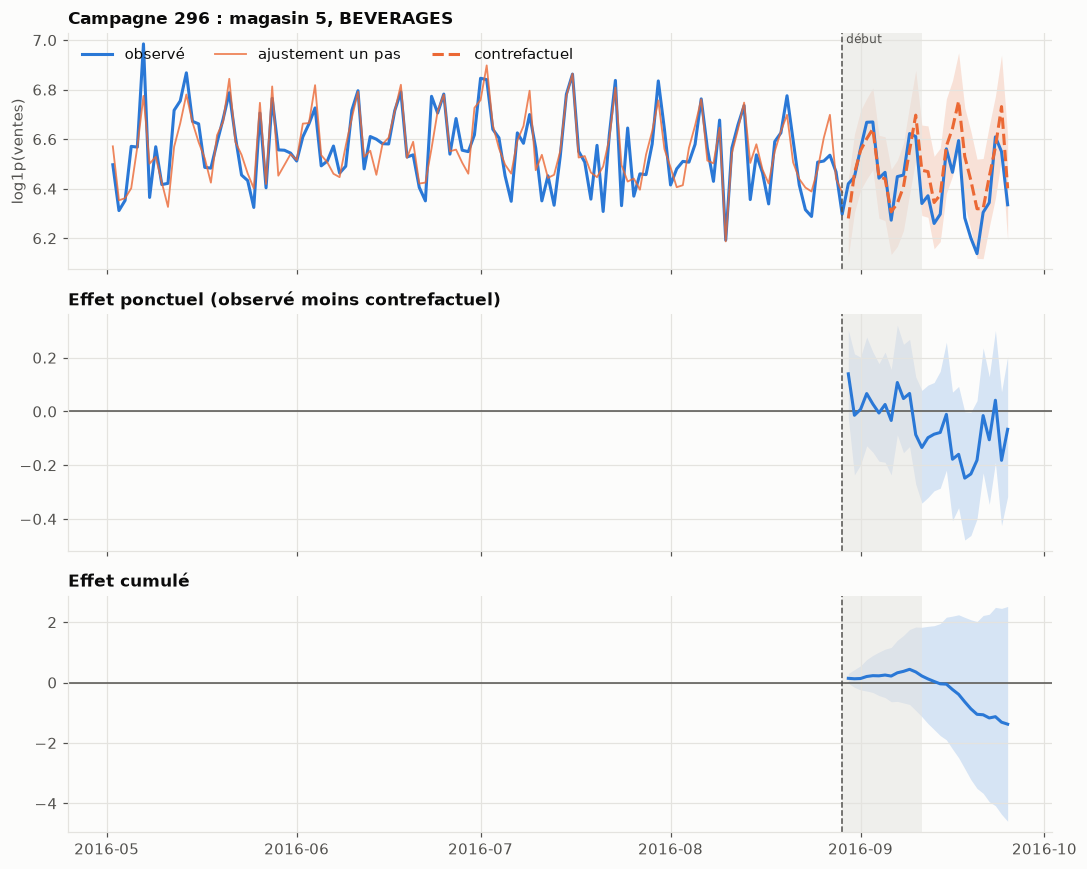

In [3]:
fig, axes = viz.plot_impact(r, f"Campagne {cid} : magasin {camp['store_nbr']}, {camp['family']}",
                            campaign_end=camp["end"])
export(fig, "nb03_impact")
plt.show()

**Attention.** L'effet sur l'échelle `log1p` n'est pas l'effet en unités : `exp(moyenne)` sous-estime la
moyenne d'une lognormale. Les unités se lisent **trajectoire par trajectoire** : chaque trajectoire simulée du
contrefactuel est ramenée en ventes, sommée sur la fenêtre, et l'effet est la différence avec l'observé. Les
quantiles de ces différences donnent l'intervalle. Le net inclut le creux après la campagne.

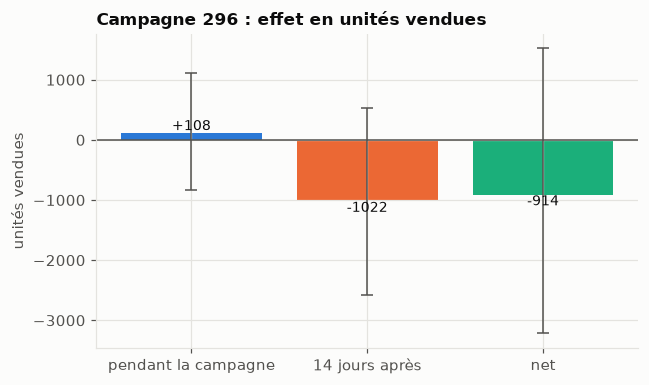

pendant : +108 [-842 ; +1113] soit +1.6% ; après : -1022 ; net : -914 [-3217 ; +1521] ; part reprise par le pull-forward : 945%


In [4]:
fig, ax = viz.plot_units_effects(est.units, f"Campagne {cid} : effet en unités vendues")
export(fig, "nb03_units")
plt.show()
u = est.units
print(f"pendant : {u['during_units']:+.0f} [{u['during_lower']:+.0f} ; {u['during_upper']:+.0f}] "
      f"soit {u['during_rel']:+.1%} ; après : {u['after_units']:+.0f} ; net : {u['net_units']:+.0f} "
      f"[{u['net_lower']:+.0f} ; {u['net_upper']:+.0f}] ; part reprise par le pull-forward : {u['pull_forward_share']:.0%}")

## 3. Placebo dans le temps : le design sur des dates où rien ne s'est passé

**Intuition.** On rejoue la même analyse avec huit fausses dates dans la pré-période, en tronquant les données
à la vraie date pour qu'aucune donnée traitée ne fuie. Chaque fausse date devrait donner un effet dont
l'intervalle contient zéro. Ce test valide le modèle de pré-période ; il ne voit **pas** la contamination des
donneurs (notebook 04 le mesure sur vérité plantée). Le protocole tolère deux intervalles sur huit qui excluent
zéro : la veille a mesuré que ce placebo se déclenche dans 11 à 17 % des cas sur des panels propres.

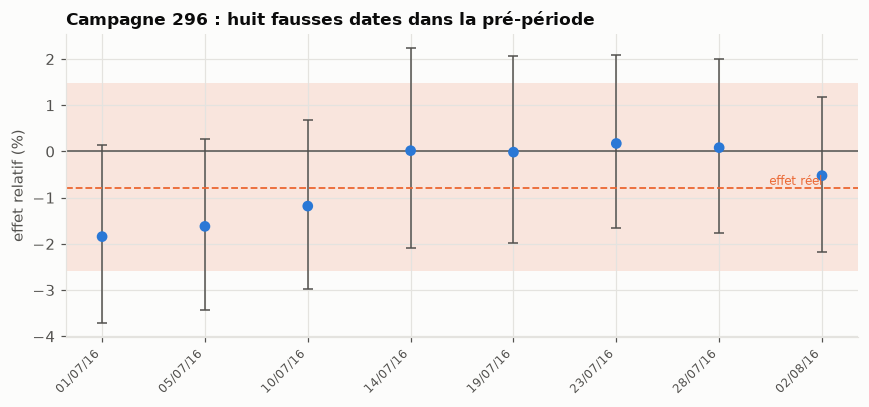

0 fausse(s) date(s) sur 8 dont l'intervalle exclut zéro


In [5]:
sweep = placebo_time(y, X, camp, n_dates=PROTOCOL["placebo_dates"], nsim=1500)
fig, ax = viz.plot_placebo_sweep(sweep, r.summary(), f"Campagne {cid} : huit fausses dates dans la pré-période")
export(fig, "nb03_placebo_time")
plt.show()
print(f"{int(sweep['excludes_zero'].sum())} fausse(s) date(s) sur {len(sweep)} dont l'intervalle exclut zéro")

## 4. Placebo dans l'espace et isolation : les donneurs ont-ils bougé avec la campagne ?

**Intuition.** Chaque donneur est traité à son tour comme s'il était la cible, avec les autres donneurs et le
calendrier comme régresseurs, à la vraie date. Un donneur dont l'« effet propre » exclut zéro a bougé avec la
campagne (cannibalisation si négatif, halo si positif) : il contamine le contrefactuel. Un donneur contaminé
contamine aussi le placebo des autres, d'où l'isolation *leave-one-out* : retirer le plus suspect, rejouer,
jusqu'à ce que plus rien ne soit signalé. La cible doit se classer parmi les plus grands effets.

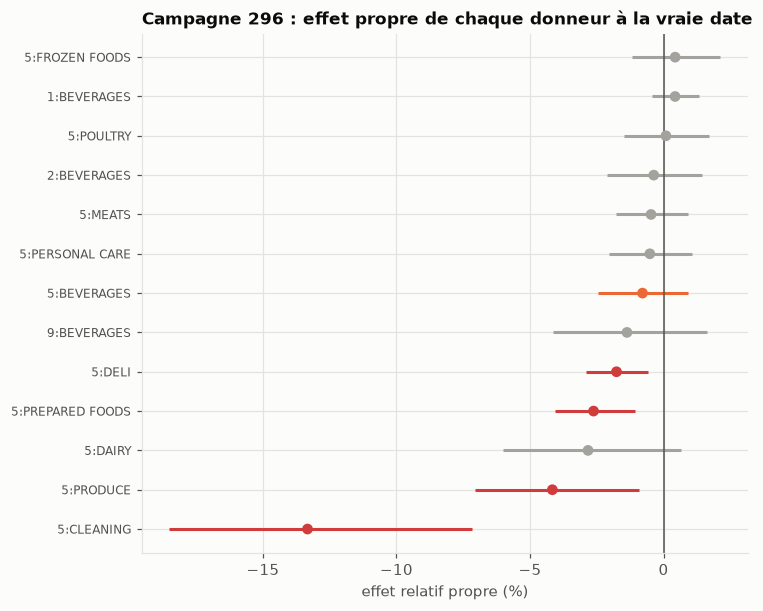

rang de la cible par |effet relatif| : p = 0.54
donneurs retirés par l'isolation : [(5, 'CLEANING'), (5, 'PREPARED FOODS'), (5, 'DELI'), (5, 'PRODUCE')]


In [6]:
space = placebo_space(w.wide, w.calendars, camp, pool, nsim=1500)
fig, ax = viz.plot_space_ranking(space, f"Campagne {cid} : effet propre de chaque donneur à la vraie date")
export(fig, "nb03_placebo_space")
plt.show()
removed, kept_pool, first = isolate(w.wide, w.calendars, camp, pool, nsim=1500)
print(f"rang de la cible par |effet relatif| : p = {space.loc[space['is_treated'], 'rank_p_rel'].iloc[0]:.2f}")
print(f"donneurs retirés par l'isolation : {removed if removed else 'aucun'}")

## 5. Sensibilité au pool

**Attention.** Le plafond de 12 donneurs et le classement par corrélation sont des choix. La figure montre
l'effet relatif sans aucun donneur (niveau local + calendrier seuls), avec 3, 6, 9, 12 donneurs, puis en
retirant chaque donneur du pool à tour de rôle. Un effet qui change de signe selon le pool n'est pas un résultat.

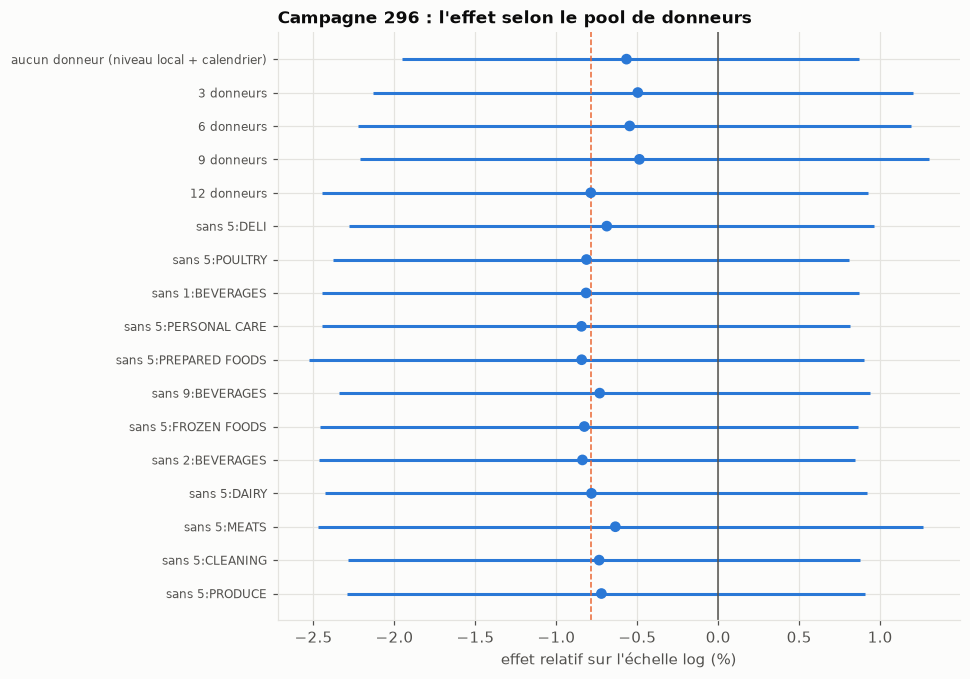

In [7]:
sens = pool_sensitivity(w.wide, w.calendars, camp, tab, nsim=1500)
fig, ax = plt.subplots(figsize=(8, 0.32 * len(sens) + 1.5))
ypos = np.arange(len(sens))
colors = [viz.CRITICAL if e else viz.BLUE for e in sens["excludes_zero"]]
ax.hlines(ypos, sens["rel_lower"] * 100, sens["rel_upper"] * 100, color=colors, linewidth=2)
ax.scatter(sens["rel_effect"] * 100, ypos, c=colors, zorder=3)
ax.axvline(0, color=viz.TEXT_2, linewidth=1)
ax.axvline(r.summary()["rel_effect"] * 100, color=viz.ORANGE, linestyle="--", linewidth=1)
ax.set_yticks(ypos, sens.index, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("effet relatif sur l'échelle log (%)")
ax.set_title(f"Campagne {cid} : l'effet selon le pool de donneurs")
export(fig, "nb03_pool_sensitivity")
plt.show()

## 6. Les autres estimateurs sur la même campagne

**Exemple.** Même cible, mêmes donneurs, même pré-période : régression statique (espace d'états sans niveau
stochastique), OLS, contrôle synthétique convexe, contrôle synthétique augmenté, différence de différences.
Leurs intervalles sont ceux qu'un praticien calculerait (erreurs iid). La veille a montré qu'ils sont
six à sept fois trop étroits sur des séries autocorrélées ; le notebook 04 le mesure ici sur vérité plantée.

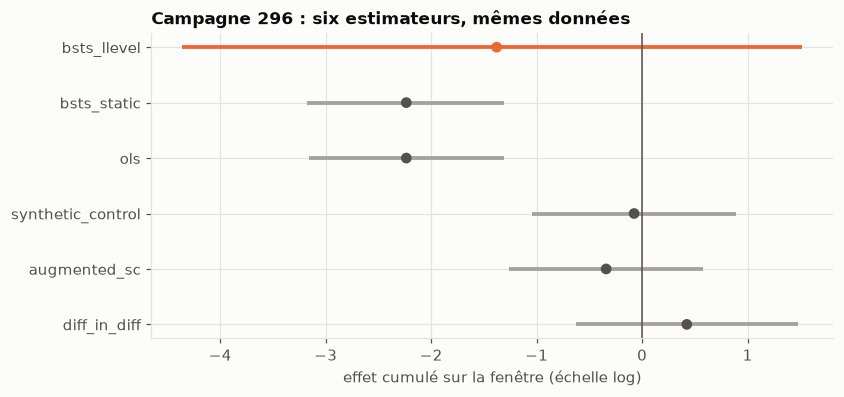

                   effet cumulé (log)  lower  upper
estimateur                                         
bsts_llevel                    -1.379 -4.359  1.520
bsts_static                    -2.236 -3.177 -1.308
ols                            -2.236 -3.163 -1.309
synthetic_control              -0.076 -1.043  0.891
augmented_sc                   -0.341 -1.264  0.582
diff_in_diff                    0.424 -0.628  1.476


In [8]:
pre_end = pd.Timestamp(camp["start"]) - pd.Timedelta(1, unit="D")
rows = []
for name, fn in ESTIMATORS.items():
    e = fn(y, X, pre_end)
    rows.append({"estimateur": name, "effet cumulé (log)": e.cum_effect, "lower": e.cum_lower, "upper": e.cum_upper})
cmp = pd.DataFrame(rows).set_index("estimateur")
fig, ax = plt.subplots(figsize=(8, 3.6))
ypos = np.arange(len(cmp))
ax.hlines(ypos, cmp["lower"], cmp["upper"], color=[viz.ORANGE if i == "bsts_llevel" else viz.MUTED for i in cmp.index],
          linewidth=2.5)
ax.scatter(cmp["effet cumulé (log)"], ypos, c=[viz.ORANGE if i == "bsts_llevel" else viz.TEXT_2 for i in cmp.index],
           zorder=3)
ax.axvline(0, color=viz.TEXT_2, linewidth=1)
ax.set_yticks(ypos, cmp.index)
ax.invert_yaxis()
ax.set_xlabel("effet cumulé sur la fenêtre (échelle log)")
ax.set_title(f"Campagne {cid} : six estimateurs, mêmes données")
export(fig, "nb03_estimators")
plt.show()
print(cmp.round(3).to_string())

## 7. Le verdict

Le protocole (`plan.md`, section 4) ne note pas la taille de l'effet, il note la **crédibilité** de la mesure :
ajustement de pré-période, placebo dans le temps, isolation. Une campagne qui échoue est « non mesurable », et
ce verdict est un résultat : il dit que le design ne sait pas lire cette série, pas que la campagne n'a rien fait.

In [9]:
verdict = credibility(est.quality, sweep, removed)
print(pd.Series(verdict).to_string())

check_fit_r2                 True
check_fit_coverage           True
check_fit_ljung_box          True
check_placebo_in_time        True
check_donor_isolation        True
value_fit_r2             0.730716
value_fit_coverage       0.943396
value_fit_ljung_box      0.318619
value_placebo_in_time           0
value_donor_isolation           4
measurable                   True


## À retenir

- Le contrefactuel est une prévision ; son crédit vient de la pré-période (ajustement un pas en avant) et des
  placebos, pas de l'allure de la courbe.
- Les unités se lisent trajectoire par trajectoire ; le net inclut le creux après la campagne.
- Le placebo dans le temps valide le modèle, le placebo dans l'espace valide les donneurs ; les deux sont
  nécessaires et aucun ne voit une relation qui casse à la date de campagne.
- Le pool est un choix : on le montre, on ne le cache pas.